<a href="https://colab.research.google.com/github/miriamamin1213-ux/ValidationSET/blob/main/HancockGPT2Gen.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Device: cuda
Eligible patients: 332
Features: ['age_at_initial_diagnosis', 'sex', 'smoking_status', 'primary_tumor_site', 'primarily_metastasis']
Training patients: 215 | Class counts: [123  92]
Validation patients: 50 | Class counts: [29 21]
Test patients: 67 | Class counts: [39 28]
Example input:
 Q: This patient is 53 years old. Sex: male. Smoking status: smoker. Primary tumour site: Oropharynx. Primary metastasis status: no. Is this patient HPV positive? Answer with only Yes or No.
A:
Example target: No

HANCOCK token length analysis
Number of patients: 332
Prompt length - minimum: 49
Prompt length - median: 51
Prompt length - 95th percentile: 54
Prompt length - maximum: 54
Target length - maximum, including EOS: 2
Combined length - maximum: 56

Selected MAX_LENGTH: 56
Examples exceeding MAX_LENGTH: 0/332
Batch size: 64 | Epochs: 500
Dataset sizes: 215 50 67
Selected maximum length: 56


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT-2 hidden size: 768 | Layers: 12 | Heads: 12
Training class weights: [0.87398374 1.1684783 ]
Epoch 50/500 | Train Loss=0.2768 | Val Loss=0.4132 | Val ROC-AUC=0.6043 | Val PR-AUC=0.5319 | Val BA=0.6223 | Val threshold=0.209062
Epoch 100/500 | Train Loss=0.2114 | Val Loss=0.5967 | Val ROC-AUC=0.5493 | Val PR-AUC=0.4971 | Val BA=0.5788 | Val threshold=0.564473
Epoch 150/500 | Train Loss=0.2059 | Val Loss=1.0850 | Val ROC-AUC=0.5690 | Val PR-AUC=0.5311 | Val BA=0.6149 | Val threshold=0.888207
Epoch 200/500 | Train Loss=0.1770 | Val Loss=0.8730 | Val ROC-AUC=0.5632 | Val PR-AUC=0.5331 | Val BA=0.6149 | Val threshold=0.942182
Epoch 250/500 | Train Loss=0.1615 | Val Loss=2.3844 | Val ROC-AUC=0.5041 | Val PR-AUC=0.4841 | Val BA=0.5722 | Val threshold=0.388152
Epoch 300/500 | Train Loss=0.1577 | Val Loss=2.6746 | Val ROC-AUC=0.4951 | Val PR-AUC=0.4457 | Val BA=0.5936 | Val threshold=0.686731
Epoch 350/500 | Train Loss=0.1609 | Val Loss=1.3712 | Val ROC-AUC=0.4885 | Val PR-AUC=0.4430 | Val BA

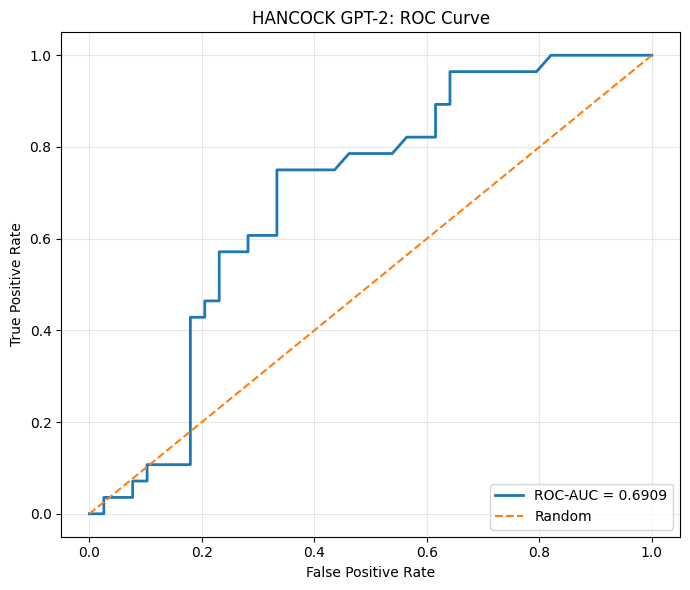

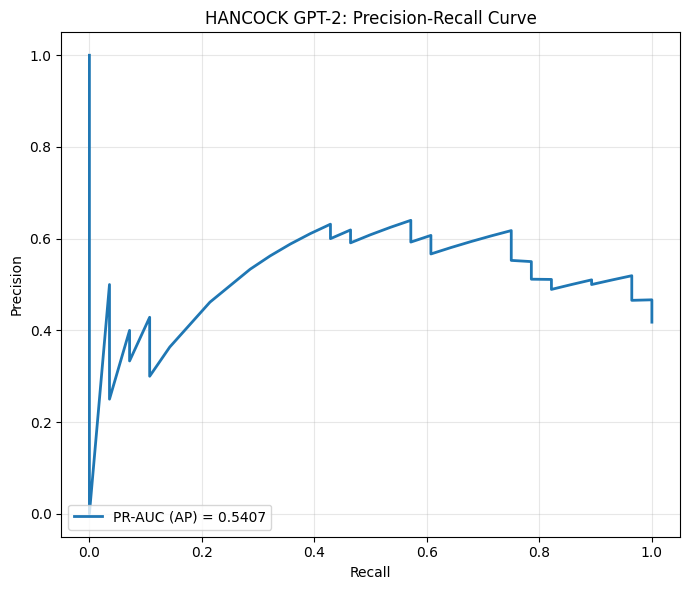


Saved outputs to: /content/ROC_HANCOCK_GPT2
Optimizer: AdamW | Learning rate: 0.001 | Weight decay: 0.0001
Gradient clipping: None | Early stopping: None
Epochs: 500 | Batch size: 64 | Maximum length: 56


In [3]:
# ============================================================
# 1. IMPORTS AND REPRODUCIBILITY
# ============================================================
import os, random, json, math, gdown
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from transformers import GPT2Tokenizer, GPT2LMHeadModel
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, balanced_accuracy_score, roc_auc_score,
    average_precision_score, confusion_matrix, roc_curve,
    precision_recall_curve
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ============================================================
# 2. LOAD AND PREPARE HANCOCK DATA
# ============================================================
for file, file_id in [
    ("clinical_data.json", "1F_kngwHn6KkOQqSwtYXCaF-bT8DZt__Q"),
    ("pathological_data.json", "1KY3NS9q3lfodf-t3g92S1JE3Vqcl6o3F")
]:
    if not os.path.exists(file):
        result = gdown.download(id=file_id, output=file, quiet=False)
        if result is None or not os.path.exists(file):
            raise FileNotFoundError(f"Could not download {file}; upload it manually.")

with open("clinical_data.json") as f:
    clinical = pd.DataFrame(json.load(f))
with open("pathological_data.json") as f:
    pathology = pd.DataFrame(json.load(f))

df = clinical.merge(pathology, on="patient_id", how="inner")
df = df[df["hpv_association_p16"].isin(["positive", "negative"])].copy()
df["HPV"] = df["hpv_association_p16"].map({"negative": 0, "positive": 1})

features = [
    "age_at_initial_diagnosis",
    "sex",
    "smoking_status",
    "primary_tumor_site",
    "primarily_metastasis"
]

missing_features = [c for c in features if c not in df.columns]
if missing_features:
    raise KeyError(f"Missing required feature columns: {missing_features}")

df = df.dropna(subset=["HPV"]).copy()
print("Eligible patients:", len(df))
print("Features:", features)

# ============================================================
# 3. STRATIFIED TRAIN, VALIDATION AND TEST SPLITS
# ============================================================
data = df[features + ["HPV"]].copy()
train_val_df, test_df = train_test_split(
    data, test_size=0.20, random_state=SEED, stratify=data["HPV"]
)
train_df, val_df = train_test_split(
    train_val_df, test_size=0.1875, random_state=SEED,
    stratify=train_val_df["HPV"]
)
train_df, val_df, test_df = train_df.copy(), val_df.copy(), test_df.copy()

# Fit imputation values on training data only.
fill_values = {}
for col in features:
    if pd.api.types.is_numeric_dtype(train_df[col]):
        value = train_df[col].median()
    else:
        modes = train_df[col].mode(dropna=True)
        value = modes.iloc[0] if not modes.empty else "Unknown"
    fill_values[col] = value
    for split in (train_df, val_df, test_df):
        split[col] = split[col].fillna(value)
        if split[col].dtype == object:
            split[col] = split[col].replace("", "Unknown")

y_train = train_df["HPV"].astype(int).to_numpy()
y_val = val_df["HPV"].astype(int).to_numpy()
y_test = test_df["HPV"].astype(int).to_numpy()

print("Training patients:", len(train_df), "| Class counts:", np.bincount(y_train, minlength=2))
print("Validation patients:", len(val_df), "| Class counts:", np.bincount(y_val, minlength=2))
print("Test patients:", len(test_df), "| Class counts:", np.bincount(y_test, minlength=2))

# ============================================================
# 4. CREATE CLINICAL NARRATIVES AND YES/NO TARGETS
# ============================================================
def patient_to_text(row):
    return (
        f"Q: This patient is {row['age_at_initial_diagnosis']} years old. "
        f"Sex: {row['sex']}. "
        f"Smoking status: {row['smoking_status']}. "
        f"Primary tumour site: {row['primary_tumor_site']}. "
        f"Primary metastasis status: {row['primarily_metastasis']}. "
        "Is this patient HPV positive? Answer with only Yes or No.\nA:"
    )

train_texts = [patient_to_text(r) for _, r in train_df.iterrows()]
val_texts = [patient_to_text(r) for _, r in val_df.iterrows()]
test_texts = [patient_to_text(r) for _, r in test_df.iterrows()]

def make_targets(labels):
    return ["Yes" if y == 1 else "No" for y in labels]

train_targets = make_targets(y_train)
val_targets = make_targets(y_val)
test_targets = make_targets(y_test)

print("Example input:\n", train_texts[0])
print("Example target:", train_targets[0])

# ============================================================
# 5. TOKENIZER, TOKEN LENGTH ANALYSIS AND MAX_LENGTH SELECTION
# ============================================================
MODEL_NAME = "openai-community/gpt2"
BATCH_SIZE = 64
EPOCHS = 500
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

tokenizer = GPT2Tokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token

# Measure every prompt and target before selecting MAX_LENGTH.
# Use the same length-selection procedure as the HECKTOR notebook.
all_texts = train_texts + val_texts + test_texts
all_targets = train_targets + val_targets + test_targets

prompt_lengths = [
    len(tokenizer.encode(text, add_special_tokens=False))
    for text in all_texts
]
target_lengths = [
    len(tokenizer.encode(" " + target, add_special_tokens=False)) + 1
    for target in all_targets
]  # +1 for the EOS token

combined_lengths = [
    p + t for p, t in zip(prompt_lengths, target_lengths)
]

print("\nHANCOCK token length analysis")
print("Number of patients:", len(combined_lengths))
print("Prompt length - minimum:", min(prompt_lengths))
print("Prompt length - median:", int(np.median(prompt_lengths)))
print("Prompt length - 95th percentile:", int(np.percentile(prompt_lengths, 95)))
print("Prompt length - maximum:", max(prompt_lengths))
print("Target length - maximum, including EOS:", max(target_lengths))
print("Combined length - maximum:", max(combined_lengths))

# Round the longest observed combined length up to a multiple of 8.
# Apply the same minimum and maximum limits as HECKTOR.
MAX_LENGTH = max(32, math.ceil(max(combined_lengths) / 8) * 8)
MAX_LENGTH = min(MAX_LENGTH, 1024)

truncated_count = sum(length > MAX_LENGTH for length in combined_lengths)

print("\nSelected MAX_LENGTH:", MAX_LENGTH)
print(f"Examples exceeding MAX_LENGTH: {truncated_count}/{len(combined_lengths)}")
if max(combined_lengths) > 1024:
    print("WARNING: Some examples exceed 1024 tokens; prompts may be truncated.")

print("Batch size:", BATCH_SIZE, "| Epochs:", EPOCHS)

# ============================================================
# 6. GENERATIVE DATASETS AND DATALOADERS
# ============================================================
class GPT2GenerationDataset(Dataset):
    def __init__(self, texts, targets, labels):
        self.items = []
        for text, target, label in zip(texts, targets, labels):
            prompt_ids = tokenizer.encode(text, add_special_tokens=False)
            target_ids = tokenizer.encode(" " + target, add_special_tokens=False)
            target_ids += [tokenizer.eos_token_id]

            # Preserve the complete target; truncate the prompt if necessary.
            prompt_ids = prompt_ids[:max(0, MAX_LENGTH - len(target_ids))]
            ids = prompt_ids + target_ids
            loss_labels = [-100] * len(prompt_ids) + target_ids
            pad_len = MAX_LENGTH - len(ids)

            self.items.append((
                ids + [tokenizer.pad_token_id] * pad_len,
                [1] * len(ids) + [0] * pad_len,
                loss_labels + [-100] * pad_len,
                int(label)
            ))

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        ids, mask, labels, cls = self.items[idx]
        return {
            "input_ids": torch.tensor(ids, dtype=torch.long),
            "attention_mask": torch.tensor(mask, dtype=torch.long),
            "labels": torch.tensor(labels, dtype=torch.long),
            "class_label": torch.tensor(cls, dtype=torch.long)
        }

train_dataset = GPT2GenerationDataset(train_texts, train_targets, y_train)
val_dataset = GPT2GenerationDataset(val_texts, val_targets, y_val)
test_dataset = GPT2GenerationDataset(test_texts, test_targets, y_test)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("Dataset sizes:", len(train_dataset), len(val_dataset), len(test_dataset))
print("Selected maximum length:", MAX_LENGTH)

# ============================================================
# 7. LOAD GPT-2 AND SET TRAINING-ONLY CLASS WEIGHTS
# ============================================================
model = GPT2LMHeadModel.from_pretrained(MODEL_NAME).to(device)
model.config.pad_token_id = tokenizer.pad_token_id

print(
    "GPT-2 hidden size:", model.config.n_embd,
    "| Layers:", model.config.n_layer,
    "| Heads:", model.config.n_head
)

class_counts = np.bincount(y_train, minlength=2)
class_weights = torch.tensor(
    len(y_train) / (2 * np.maximum(class_counts, 1)),
    dtype=torch.float32, device=device
)
print("Training class weights:", class_weights.detach().cpu().numpy())

optimizer = torch.optim.AdamW(
    model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
)

# ============================================================
# 8. WEIGHTED GENERATION LOSS AND LOSS EVALUATION
# ============================================================
def weighted_generation_loss(logits, labels, class_labels):
    shift_logits = logits[:, :-1, :].contiguous()
    shift_labels = labels[:, 1:].contiguous()

    token_loss = nn.CrossEntropyLoss(reduction="none")(
        shift_logits.reshape(-1, shift_logits.size(-1)),
        shift_labels.reshape(-1)
    ).view(shift_labels.size(0), -1)

    valid = (shift_labels != -100).float()
    example_loss = (token_loss * valid).sum(1) / valid.sum(1).clamp(min=1)
    return (example_loss * class_weights[class_labels]).mean()

def evaluate_loss(loader):
    model.eval()
    total_loss, total_batches = 0.0, 0
    with torch.no_grad():
        for batch in loader:
            ids = batch["input_ids"].to(device)
            mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)
            classes = batch["class_label"].to(device)

            logits = model(input_ids=ids, attention_mask=mask).logits
            loss = weighted_generation_loss(logits, labels, classes)
            total_loss += loss.item()
            total_batches += 1

    return total_loss / max(total_batches, 1)

# ============================================================
# 9. CONTINUOUS YES/NO SCORES AND VALIDATION THRESHOLD
# ============================================================
# Score = P(Yes) / [P(Yes) + P(No)] at the next-token position.
yes_ids = tokenizer.encode(" Yes", add_special_tokens=False)
no_ids = tokenizer.encode(" No", add_special_tokens=False)

if len(yes_ids) != 1 or len(no_ids) != 1:
    raise ValueError("Expected ' Yes' and ' No' to each be a single GPT-2 token.")

YES_TOKEN_ID, NO_TOKEN_ID = yes_ids[0], no_ids[0]

def get_hpv_scores(prompts, batch_size=BATCH_SIZE):
    model.eval()
    scores = []

    with torch.no_grad():
        for start_idx in range(0, len(prompts), batch_size):
            batch_prompts = prompts[start_idx:start_idx + batch_size]
            encoded = tokenizer(
                batch_prompts, return_tensors="pt", padding=True,
                truncation=True, max_length=MAX_LENGTH
            ).to(device)

            logits = model(
                input_ids=encoded["input_ids"],
                attention_mask=encoded["attention_mask"]
            ).logits

            last_positions = encoded["attention_mask"].sum(dim=1) - 1
            next_logits = logits[
                torch.arange(len(batch_prompts), device=device), last_positions
            ]

            probs = torch.softmax(next_logits, dim=-1)
            yes_probs = probs[:, YES_TOKEN_ID]
            no_probs = probs[:, NO_TOKEN_ID]

            scores.extend(
                (yes_probs / (yes_probs + no_probs).clamp(min=1e-12)).cpu().numpy()
            )

    return np.asarray(scores, dtype=float)

def select_threshold(scores, labels):
    # Select the threshold that maximises validation balanced accuracy.
    thresholds = np.unique(np.concatenate(([0.0], scores, [1.0])))
    results = [
        (float(t), balanced_accuracy_score(labels, (scores >= t).astype(int)))
        for t in thresholds
    ]
    best_threshold, best_ba = max(results, key=lambda x: x[1])
    return best_threshold, best_ba, results

# ============================================================
# 10. TRAIN 500 EPOCHS AND SAVE BEST CHECKPOINT FOR EACH METRIC
# ============================================================
out_dir = Path("ROC_HANCOCK_GPT2")
out_dir.mkdir(parents=True, exist_ok=True)

checkpoint_paths = {
    "Validation_Loss": out_dir / "best_model_validation_loss.pth",
    "Validation_ROC_AUC": out_dir / "best_model_validation_roc_auc.pth",
    "Validation_PR_AUC": out_dir / "best_model_validation_pr_auc.pth",
    "Validation_Balanced_Accuracy": out_dir / "best_model_validation_balanced_accuracy.pth"
}

best = {
    "Validation_Loss": {"value": float("inf"), "epoch": None, "threshold": None},
    "Validation_ROC_AUC": {"value": -float("inf"), "epoch": None, "threshold": None},
    "Validation_PR_AUC": {"value": -float("inf"), "epoch": None, "threshold": None},
    "Validation_Balanced_Accuracy": {"value": -float("inf"), "epoch": None, "threshold": None}
}
history = []

for epoch in range(1, EPOCHS + 1):
    model.train()
    train_total, train_batches = 0.0, 0

    for batch in train_loader:
        ids = batch["input_ids"].to(device)
        mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)
        classes = batch["class_label"].to(device)

        optimizer.zero_grad(set_to_none=True)
        logits = model(input_ids=ids, attention_mask=mask).logits
        loss = weighted_generation_loss(logits, labels, classes)
        loss.backward()
        # No gradient clipping.
        optimizer.step()

        train_total += loss.item()
        train_batches += 1

    train_loss = train_total / max(train_batches, 1)
    val_loss = evaluate_loss(val_loader)

    # Calculate validation metrics for this epoch's model.
    val_scores = get_hpv_scores(val_texts)
    val_auc = roc_auc_score(y_val, val_scores)
    val_ap = average_precision_score(y_val, val_scores)
    val_threshold, val_ba, _ = select_threshold(val_scores, y_val)

    history.append({
        "Epoch": epoch,
        "Train_Loss": train_loss,
        "Validation_Loss": val_loss,
        "Validation_ROC_AUC": val_auc,
        "Validation_PR_AUC": val_ap,
        "Validation_Balanced_Accuracy": val_ba,
        "Validation_Threshold": val_threshold
    })

    if val_loss < best["Validation_Loss"]["value"]:
        best["Validation_Loss"] = {
            "value": val_loss, "epoch": epoch, "threshold": val_threshold
        }
        torch.save(model.state_dict(), checkpoint_paths["Validation_Loss"])

    if val_auc > best["Validation_ROC_AUC"]["value"]:
        best["Validation_ROC_AUC"] = {
            "value": val_auc, "epoch": epoch, "threshold": val_threshold
        }
        torch.save(model.state_dict(), checkpoint_paths["Validation_ROC_AUC"])

    if val_ap > best["Validation_PR_AUC"]["value"]:
        best["Validation_PR_AUC"] = {
            "value": val_ap, "epoch": epoch, "threshold": val_threshold
        }
        torch.save(model.state_dict(), checkpoint_paths["Validation_PR_AUC"])

    if val_ba > best["Validation_Balanced_Accuracy"]["value"]:
        best["Validation_Balanced_Accuracy"] = {
            "value": val_ba, "epoch": epoch, "threshold": val_threshold
        }
        torch.save(
            model.state_dict(),
            checkpoint_paths["Validation_Balanced_Accuracy"]
        )

    if epoch % 50 == 0:
        print(
            f"Epoch {epoch}/{EPOCHS} | Train Loss={train_loss:.4f} | "
            f"Val Loss={val_loss:.4f} | Val ROC-AUC={val_auc:.4f} | "
            f"Val PR-AUC={val_ap:.4f} | Val BA={val_ba:.4f} | "
            f"Val threshold={val_threshold:.6f}"
        )

# Save epoch history and best-checkpoint summary.
history_df = pd.DataFrame(history)
history_df.to_csv(out_dir / "training_history.csv", index=False)

best_summary = pd.DataFrame([
    {
        "Checkpoint_Selected_By": metric,
        "Best_Epoch": info["epoch"],
        "Best_Validation_Metric": info["value"],
        "Threshold_Selected_On_Validation": info["threshold"],
        "Checkpoint_Path": str(checkpoint_paths[metric])
    }
    for metric, info in best.items()
])
best_summary.to_csv(out_dir / "best_validation_checkpoints.csv", index=False)

print("\n===== BEST VALIDATION CHECKPOINTS =====")
print(best_summary.to_string(index=False))

# ============================================================
# 11. FINAL TEST EVALUATION FOR EACH PRESELECTED CHECKPOINT
# ============================================================
# Test data does not select epochs, checkpoints or thresholds.
test_results = []
test_predictions = {}

for metric, checkpoint_path in checkpoint_paths.items():
    print(f"\n===== Checkpoint selected by {metric} =====")
    model.load_state_dict(torch.load(checkpoint_path, map_location=device))
    test_scores = get_hpv_scores(test_texts)

    threshold = best[metric]["threshold"]
    test_pred = (test_scores >= threshold).astype(int)

    test_auc = roc_auc_score(y_test, test_scores)
    test_ap = average_precision_score(y_test, test_scores)
    test_ba = balanced_accuracy_score(y_test, test_pred)
    test_cm = confusion_matrix(y_test, test_pred, labels=[0, 1])

    print("Best validation epoch:", best[metric]["epoch"])
    print("Best validation metric:", round(best[metric]["value"], 4))
    print(f"Threshold selected on validation: {threshold:.6f}")
    print(classification_report(
        y_test, test_pred, labels=[0, 1],
        target_names=["HPV Negative", "HPV Positive"],
        digits=4, zero_division=0
    ))
    print(f"Test ROC-AUC: {test_auc:.4f}")
    print(f"Test PR-AUC (Average Precision): {test_ap:.4f}")
    print(f"Test Balanced Accuracy: {test_ba:.4f}")
    print("Confusion matrix [[TN, FP], [FN, TP]]:\n", test_cm)

    test_results.append({
        "Checkpoint_Selected_By": metric,
        "Best_Epoch": best[metric]["epoch"],
        "Best_Validation_Metric": best[metric]["value"],
        "Threshold_Selected_On_Validation": threshold,
        "Test_ROC_AUC": test_auc,
        "Test_PR_AUC_Average_Precision": test_ap,
        "Test_Balanced_Accuracy": test_ba,
        "TN": int(test_cm[0, 0]),
        "FP": int(test_cm[0, 1]),
        "FN": int(test_cm[1, 0]),
        "TP": int(test_cm[1, 1])
    })

    test_predictions[metric] = {
        "scores": test_scores,
        "predictions": test_pred,
        "threshold": threshold
    }

    safe_name = metric.lower()
    pd.DataFrame({
        "True_Label": y_test,
        "HPV_Positive_Score": test_scores,
        "Predicted_Label": test_pred
    }).to_csv(out_dir / f"test_predictions_{safe_name}.csv", index=False)

test_results_df = pd.DataFrame(test_results)
test_results_df.to_csv(out_dir / "test_metrics_by_checkpoint.csv", index=False)

print("\n===== TEST RESULTS BY VALIDATION-SELECTED CHECKPOINT =====")
print(test_results_df.to_string(index=False))

# ============================================================
# 12. ROC AND PRECISION-RECALL CURVES
# ============================================================
# Curves use continuous test scores from the checkpoint selected
# by lowest validation loss.
primary_metric = "Validation_Loss"
primary_scores = test_predictions[primary_metric]["scores"]
primary_test_auc = roc_auc_score(y_test, primary_scores)
primary_test_ap = average_precision_score(y_test, primary_scores)

fpr, tpr, roc_thresholds = roc_curve(y_test, primary_scores)
pd.DataFrame({
    "FPR": fpr, "TPR": tpr, "Threshold": roc_thresholds
}).to_csv(out_dir / "roc_coordinates_validation_loss_checkpoint.csv", index=False)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, linewidth=2, label=f"ROC-AUC = {primary_test_auc:.4f}")
plt.plot([0, 1], [0, 1], "--", linewidth=1.5, label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("HANCOCK GPT-2: ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(out_dir / "roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()

precision, recall, pr_thresholds = precision_recall_curve(y_test, primary_scores)
pd.DataFrame({
    "Precision": precision, "Recall": recall
}).to_csv(out_dir / "precision_recall_coordinates_validation_loss_checkpoint.csv", index=False)

plt.figure(figsize=(7, 6))
plt.plot(recall, precision, linewidth=2, label=f"PR-AUC (AP) = {primary_test_ap:.4f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("HANCOCK GPT-2: Precision-Recall Curve")
plt.legend(loc="lower left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(out_dir / "precision_recall_curve.png", dpi=300, bbox_inches="tight")
plt.show()

# ============================================================
# 13. SAVE FINAL SETTINGS AND RESULTS
# ============================================================
settings = {
    "Model": MODEL_NAME,
    "Features": ", ".join(features),
    "Learning_Rate": LEARNING_RATE,
    "Weight_Decay": WEIGHT_DECAY,
    "Optimizer": "AdamW",
    "Gradient_Clipping": "None",
    "Early_Stopping": "None",
    "Epochs": EPOCHS,
    "Batch_Size": BATCH_SIZE,
    "Max_Length": MAX_LENGTH,
    "Max_Length_Selection": (
        "Longest observed prompt plus target length, rounded up to a multiple of 8; "
        "minimum 32, maximum 1024"
    ),
    "Random_Seed": SEED,
    "Checkpoint_Selection": (
        "Separate best validation loss, ROC-AUC, PR-AUC and balanced accuracy"
    ),
    "Threshold_Selection": (
        "Maximise balanced accuracy on validation data separately for each checkpoint"
    ),
    "Primary_ROC_PR_Curves": "Checkpoint selected by lowest validation loss"
}
pd.DataFrame([settings]).to_csv(out_dir / "settings.csv", index=False)

print("\nSaved outputs to:", out_dir.resolve())
print("Optimizer: AdamW | Learning rate:", LEARNING_RATE,
      "| Weight decay:", WEIGHT_DECAY)
print("Gradient clipping: None | Early stopping: None")
print("Epochs:", EPOCHS, "| Batch size:", BATCH_SIZE,
      "| Maximum length:", MAX_LENGTH)



In [5]:
# ============================================================
# SAVE HANCOCK ROC-AUC AND PR-AUC FOR MODEL COMPARISON
# ============================================================
comparison_file = "/content/model_roc_pr_auc_comparison.csv"

hancock_results = test_results_df[
    [
        "Checkpoint_Selected_By",
        "Best_Epoch",
        "Test_ROC_AUC",
        "Test_PR_AUC_Average_Precision"
    ]
].copy()

hancock_results.insert(0, "Model", "GPT-2")
hancock_results.insert(0, "Dataset", "HANCOCK")

# Rename columns consistently across datasets
hancock_results = hancock_results.rename(columns={
    "Test_ROC_AUC": "Test_ROC_AUC",
    "Test_PR_AUC_Average_Precision": "Test_PR_AUC"
})

# Append to the shared comparison file, preserving previous results
if os.path.exists(comparison_file):
    existing = pd.read_csv(comparison_file)
    combined = pd.concat(
        [existing, hancock_results],
        ignore_index=True
    )
    combined = combined.drop_duplicates(
        subset=["Dataset", "Model", "Checkpoint_Selected_By"],
        keep="last"
    )
else:
    combined = hancock_results

combined.to_csv(comparison_file, index=False)

print("Saved ROC-AUC and PR-AUC comparison to:", comparison_file)
print(combined.to_string(index=False))

Saved ROC-AUC and PR-AUC comparison to: /content/model_roc_pr_auc_comparison.csv
Dataset Model       Checkpoint_Selected_By  Best_Epoch  Test_ROC_AUC  Test_PR_AUC
HANCOCK GPT-2              Validation_Loss          37      0.690934     0.540728
HANCOCK GPT-2           Validation_ROC_AUC          20      0.651099     0.514154
HANCOCK GPT-2            Validation_PR_AUC          14      0.640568     0.523033
HANCOCK GPT-2 Validation_Balanced_Accuracy           9      0.611264     0.511470
